In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
import networkx as nx

from scipy import stats
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination

sys.path.insert(0, os.path.abspath("../src"))
from new_data import create_new_data

C:\Users\Rebeca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Rebeca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


# 1. a- Descreva o seu problema, seus dados, suas variáveis e a natureza de cada uma. b-Destaque a variável que deseja predizer (isto é, a variável dita dependente do modelo).

a)

O problema tem como objetivo modelar a relação entre a precipitação e o volume armazenado em açudes da região do Nordeste. 
A rede bayesiana será utilizada para estimar a probabilidade de diferentes niveis de volume dado o contexto de chuva e periodo(data)

Ideia 1: Classificar as datas em PERIODOS (ex:  tempo de chuva e tempo de seca, tempo de inverso)


![alt text](image.png)

b) 

A variável que desejamos predizer é a de Volume (hm^3) que está descrita na tabela acima. Ela será discretizada em faixas: baixo, médio e alto, por quantis ou por percentual da capacidade do açude.

As variáveis explicativas serão a de precipitação agregada(discretizada), a data(meses) e os volumes anteriores.


In [8]:
raiz = os.path.dirname(os.getcwd()) #pega o caminho da pasta raiz do projeto
pasta_1 = os.path.join(raiz, "DATA", "CSV_regioes") # viaja até a pasta que contém os CSV com data,precp e regioes
pasta_2 = os.path.join(raiz, "DATA", "CSV_acudes")  # viaja até a pasta que contém os CSV com data e volume de determinados acudes

def ler_pasta(pasta, sep=";", **kwargs):
    lista = []
    for arquivo in sorted(os.listdir(pasta)):
        if arquivo.endswith(".csv"):
            caminho = os.path.join(pasta, arquivo)
            df = pd.read_csv(caminho, sep=sep, **kwargs)
            df["arquivo"] = os.path.splitext(arquivo)[0]   # nome sem ".csv"
            lista.append(df)
    return lista

lista_dfs_precip = ler_pasta(pasta_1, sep=";", decimal=".")
lista_dfs_acude = ler_pasta(pasta_2, sep=";", decimal=",")  # ajuda com "Volume (hm³)"

df_1 = pd.concat(lista_dfs_precip, ignore_index=True)

df_2 = pd.concat(lista_dfs_acude, ignore_index=True)
df_2 = df_2.rename(columns={"arquivo": "acude"})

display(df_1)
display(df_2)

,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,precipitacao_2006_com_local
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,precipitacao_2006_com_local
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
...,...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local


,DateTime,Volume (hm³),acude
0,2006-01-01 00:00:00,42.59,reserv_atalho
1,2006-01-02 00:00:00,42.59,reserv_atalho
2,2006-01-03 00:00:00,NaN,reserv_atalho
3,2006-01-04 00:00:00,NaN,reserv_atalho
4,2006-01-05 00:00:00,NaN,reserv_atalho
...,...,...,...
30306,2026-09-26 00:00:00,40.86,reserv_rosario
30307,2026-09-27 00:00:00,40.80,reserv_rosario
30308,2026-09-28 00:00:00,40.73,reserv_rosario
30309,2026-09-29 00:00:00,40.67,reserv_rosario


# 2. No pré-processamento dos dados, realize a transformação de variáveis quantitativas em qualitativas, a partir da construção de intervalos;

---Para classificar o nivel de precipitação foi utilizado os valores adotados da escala de acumulados em 24 horas pela 

fonte:**Bustamante (2010), baseado em Moreira (2002)** que classifica:

Chuvisco [0.1, 1]

Fraca [2.0 , 10.0 )

Moderada [10.0 , 20.0)

Moderada a forte [20.0 , 30.0)

Forte [30.0 - 40.0)

Muito Forte [40.0, 50.0)

Violenta [50.0,  alem]

In [9]:
# Criando Variável Qualitativa Ordinal: Categorias de Precipitacoes
condicoes = [
    (df_1['precip_mm'] == 0.0),
    (df_1['precip_mm'] > 0.0) & (df_1['precip_mm'] <= 1.0), #chuvisco
    (df_1['precip_mm'] > 1.0) & (df_1['precip_mm'] <= 10.0), #fraco
    (df_1['precip_mm'] > 10.0) & (df_1['precip_mm'] <= 20.0), #moderado
    (df_1['precip_mm'] > 20.0) & (df_1['precip_mm'] <= 30.0), #moderado forte
    (df_1['precip_mm'] > 30.0) & (df_1['precip_mm'] <= 40.0), #forte
    (df_1['precip_mm'] > 40.0) & (df_1['precip_mm'] <= 50.0), #muito forte
    (df_1['precip_mm'] > 50.0) #violento
]

rotulos = ['Sem_Precipitação', 'Chuvisco','Fraca', 'Moderada','Moderada_a_Forte', 'Forte','Muito_Forte', 'Violenta']

df_1['classe_chuva'] = np.select(condicoes, rotulos, default='Sem Preciptação')
freq = df_1['classe_chuva'].value_counts(normalize=True).sort_index()# confere a distribuição e os valores ausentes

print(df_1['classe_chuva'].isna().sum(), "valores ausentes")

display(df_1)

0 valores ausentes


,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo,classe_chuva
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,precipitacao_2006_com_local,Fraca
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,precipitacao_2006_com_local,Moderada
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,precipitacao_2006_com_local,Moderada_a_Forte
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,precipitacao_2006_com_local,Fraca
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,precipitacao_2006_com_local,Chuvisco
...,...,...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local,Sem Preciptação
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local,Sem Preciptação
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local,Sem Preciptação
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local,Sem Preciptação


---Para classificar o nivel do volume dos acudes analisados, foi utilizado o
pct: percentual do volume em relação à capacidade máxima

pct = (volume atual/ volume da capidade maxima) *100 (retorna em porcentagem)

Classificação do volume armazenado fonte: **COGERH**

Muito critico (0 - 10 % )

Crítico (10.1 - 30%)

Alerta (30.1 a 50%)

Confortável (50.1 - 70%)

Muito confortável (70.1 - 100%)

In [10]:
capacidade = {
    "reserv_olhodgua": 19.210,
    "reserv_quixabinha": 31.780,
    "reserv_atalho": 72.550,
    "reserv_rosario": 47.220,
}

cota = {
    "reserv_olhodgua": 348.76,
    "reserv_quixabinha": 401.60,
    "reserv_atalho": 420.19,
    "reserv_rosario": 285.50,
}

vazao_perenizacao = {
    "reserv_olhodgua": 20.00,
    "reserv_quixabinha": 142.00,
    "reserv_atalho": 256.40,
    "reserv_rosario": 400.00,
}

# mapeando capacidade e cota garantindo tipo float
df_2["capacidade_maxima"] = df_2["acude"].map(capacidade).astype(float)

df_2["pct"] = (df_2["Volume (hm³)"] / df_2["capacidade_maxima"]) * 100 #calcular pct

pct_values = df_2["pct"].to_numpy() # extrair os valores em formato numpy puro para evitar o bugss

condicoes = [
    (pct_values >= 0.0) & (pct_values <= 10.0),  # muito crítico
    (pct_values > 10.0) & (pct_values <= 30.0),  # crítico
    (pct_values > 30.0) & (pct_values <= 50.0),  # alerta
    (pct_values > 50.0) & (pct_values <= 70.0),  # confortável
    (pct_values > 70.0) & (pct_values <= 100.0),  # muito confortável
]

rotulos = ["muito_critico","critico","alerta","confortavel","muito_confortavel"]

df_2["classe_acude"] = np.select(condicoes, rotulos, default="não_existe_classificacao")

display(
    df_2[
        [
            "DateTime",
            "acude",
            "Volume (hm³)",
            "capacidade_maxima",
            "pct",
            "classe_acude",
        ]
    ]
)

,DateTime,acude,Volume (hm³),capacidade_maxima,pct,classe_acude
0,2006-01-01 00:00:00,reserv_atalho,42.59,72.55,58.704342,confortavel
1,2006-01-02 00:00:00,reserv_atalho,42.59,72.55,58.704342,confortavel
2,2006-01-03 00:00:00,reserv_atalho,NaN,72.55,NaN,não_existe_classificacao
3,2006-01-04 00:00:00,reserv_atalho,NaN,72.55,NaN,não_existe_classificacao
4,2006-01-05 00:00:00,reserv_atalho,NaN,72.55,NaN,não_existe_classificacao
...,...,...,...,...,...,...
30306,2026-09-26 00:00:00,reserv_rosario,40.86,47.22,86.531131,muito_confortavel
30307,2026-09-27 00:00:00,reserv_rosario,40.80,47.22,86.404066,muito_confortavel
30308,2026-09-28 00:00:00,reserv_rosario,40.73,47.22,86.255824,muito_confortavel
30309,2026-09-29 00:00:00,reserv_rosario,40.67,47.22,86.128759,muito_confortavel


---Por fim avaliar a sazonalidade Dominante

In [ ]:
"""
Abaixo calcularemos a média mensal de precipitação em todos os anos.

Ao analizar essas médias em um gráfico poderemos ver em quais meses
a chuva se concentra mais e em quais outros meses são periodos de seca (baixa precipitaçãp).

Assim, teremos alguma ideia de como começar a fazer essa classificação de sazonalidade por datas e precipitação

"""

df_1['data'] = pd.to_datetime(df_1['data'])

df_1 = df_1[(df_1['data'].dt.year >= 2006) & (df_1['data'].dt.year <= 2026)]

df_1['ano'] = df_1['data'].dt.year
df_1['mes'] = df_1['data'].dt.month

df_mensal = df_1.groupby([ 'ano', 'mes'])['precip_mm'].sum().reset_index()
df_mensal.rename(columns={'precip_mm': 'total_mensal'}, inplace=True)

print(df_mensal)

      ano  mes   total_mensal
0    2006    1   47274.604899
1    2006    2  166821.892768
2    2006    3  246322.660521
3    2006    4  276411.398495
4    2006    5  195929.431688
..    ...  ...            ...
244  2026    5   74118.627043
245  2026    6   18157.316078
246  2026    7    7160.873207
247  2026    8    1557.062664
248  2026    9    2834.000027

[249 rows x 3 columns]


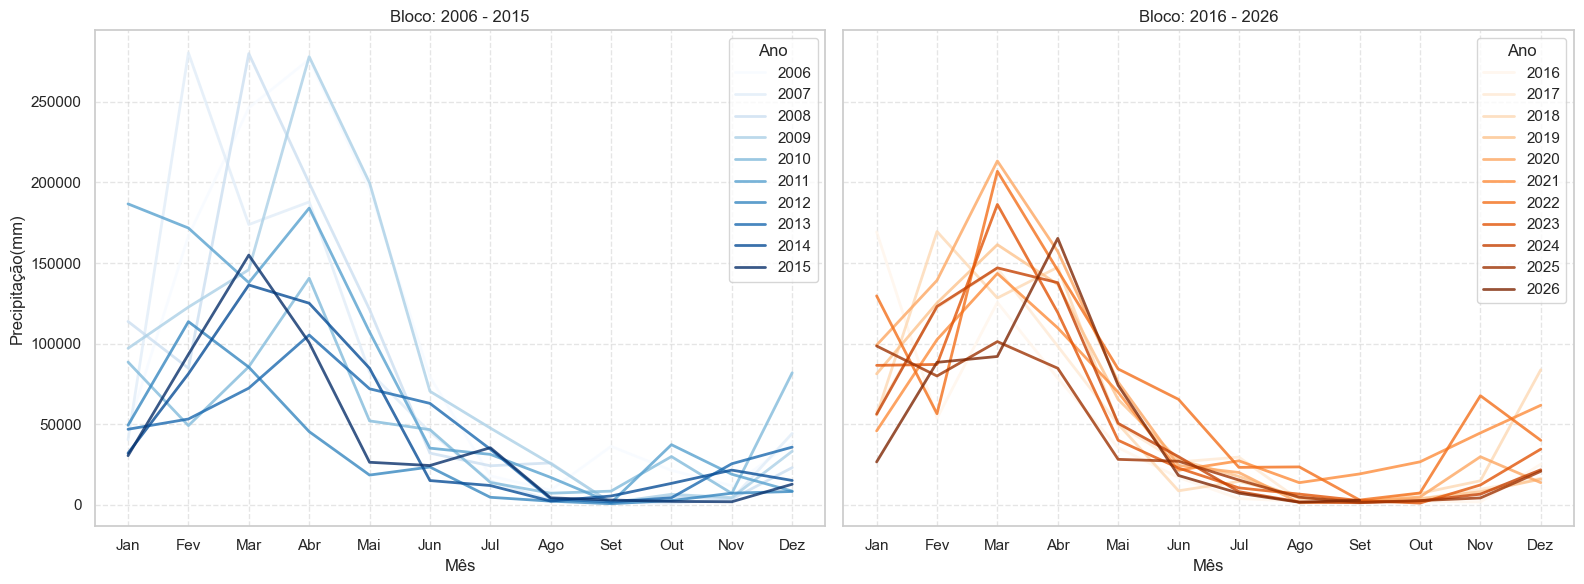

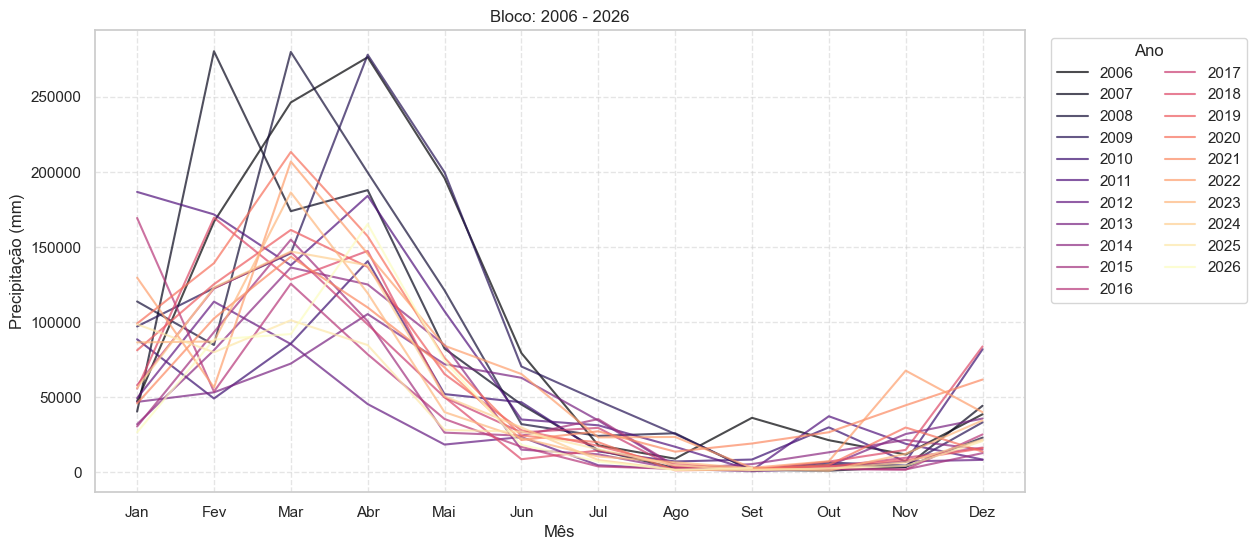

In [60]:
df_pivot = df_mensal.pivot(index='mes', columns='ano', values='total_mensal')

bloco_1 = [y for y in df_pivot.columns if 2006 <= y <= 2015]
bloco_2 = [y for y in df_pivot.columns if 2016 <= y <= 2026]

fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)

# gráfico 1 2006 a 2015
df_pivot[bloco_1].plot(ax=axes[0], cmap='Blues', alpha=0.8, linewidth=2)
axes[0].set_title('Bloco: 2006 - 2015')
axes[0].set_xlabel('Mês')
axes[0].set_ylabel('Precipitação(mm)')

axes[0].set_xticks(range(1, 13))
axes[0].set_xticklabels( ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend(title='Ano')

# gráfico 2 2016 a 2026
df_pivot[bloco_2].plot(ax=axes[1], cmap='Oranges', alpha=0.8, linewidth=2)
axes[1].set_title('Bloco: 2016 - 2026')
axes[1].set_xlabel('Mês')
axes[1].set_ylabel('Precipitação(mm)')

axes[1].set_xticks(range(1, 13))
axes[1].set_xticklabels(['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])
axes[1].grid(True, linestyle='--', alpha=0.5)
axes[1].legend(title='Ano')

plt.tight_layout()
plt.show()

#Grafico completinho

plt.figure(figsize=(12, 6))
df_pivot.plot(ax=plt.gca(), cmap='magma', alpha=0.7, linewidth=1.5)

plt.title('Bloco: 2006 - 2026')
plt.xlabel('Mês')
plt.ylabel('Precipitação (mm)')


plt.xticks(range(1, 13), ['Jan', 'Fev', 'Mar', 'Abr', 'Mai', 'Jun', 'Jul', 'Ago', 'Set', 'Out', 'Nov', 'Dez'])

plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', ncol=2, title='Ano')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()

A partir dos gráficos acima, podemos tentar começar a pensar como classificar a sazonalidade da região analisada. Observem que o periodo de chuvas começa a subir no começo de dezembro e a descer em maio-junho

C:\Users\Rebeca\AppData\Local\Temp\ipykernel_23492\1464597142.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


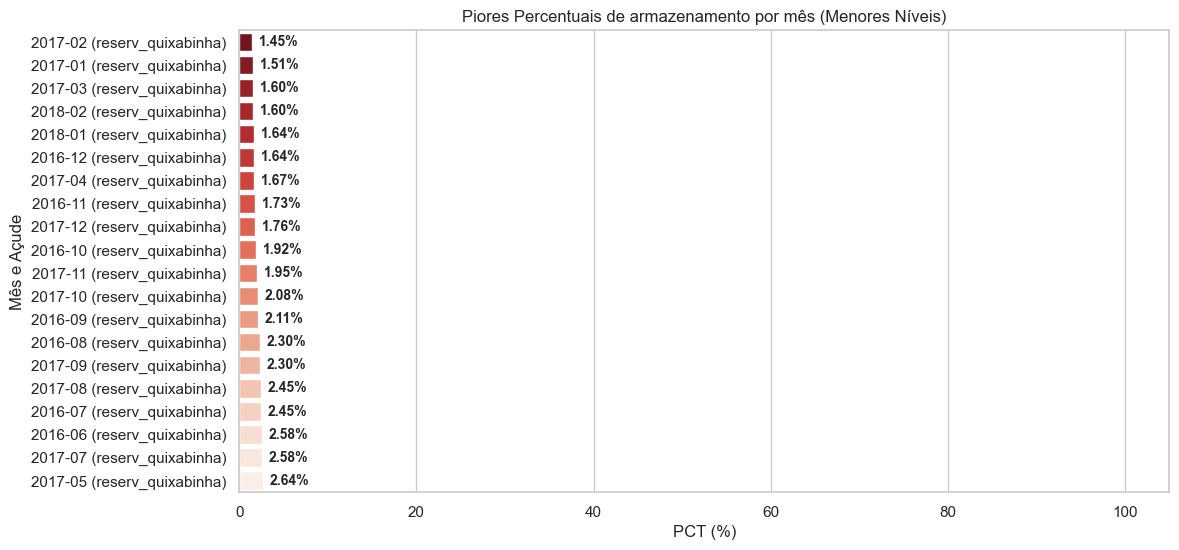

In [ ]:

# criar uma coluna com o formato Ano-Mês
df_2['AnoMes'] = df_2['DateTime'].dt.to_period('M').astype(str)

# agrupar por Açude e Mês, pegando o menor percentual (mínimo) do período
df_mensal = (df_2.groupby(['acude', 'AnoMes'])['pct'].min().reset_index())

# ordenar pelos piores percentuais e selecionar os top 
df_piores_mes = df_mensal.sort_values(by='pct', ascending=True).head(20) # <-------muda a quantidade aqui

# criar um rótulo combinando Mês e Açude para o gráfico
df_piores_mes['rotulo_mes_acude'] = (
    df_piores_mes['AnoMes'] + ' (' + df_piores_mes['acude'] + ')'
)

# configurar o estilo e gerar o gráfico de barras horizontais
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    x='pct',
    y='rotulo_mes_acude',
    data=df_piores_mes,
    palette='Reds_r',  # tons avermelhados para destacar a criticidade
)

plt.title(
    'Piores Percentuais de armazenamento por mês (Menores Níveis)'
)
plt.xlabel('PCT (%)')
plt.ylabel('Mês e Açude')

for p in ax.patches: # adicionar os valores exatos nas barras
  width = p.get_width()
  if pd.notna(width) and width > 0:
    ax.annotate(
        f'{width:.2f}%',
        xy=(width, p.get_y() + p.get_height() / 2),
        xytext=(5, 0),
        textcoords='offset points',
        ha='left',
        va='center',
        fontsize=10,
        weight='bold',
    )

plt.xlim(0, 105)
plt.show()

3. Esboce o grafo da Rede Bayesiana do seu problema;

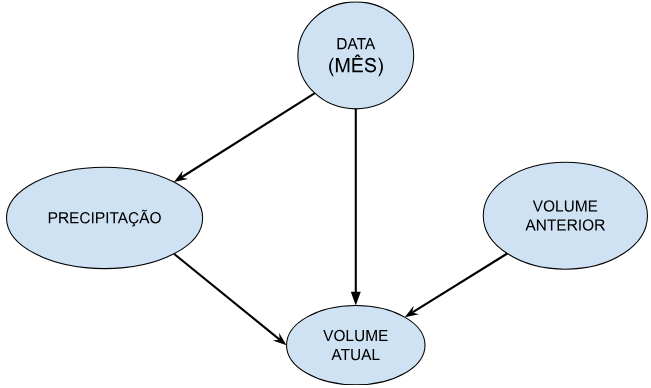

O grafo é aciclico e o volume atual, que é a variável dependente, é o único nó que recebe setas de todos os outros.

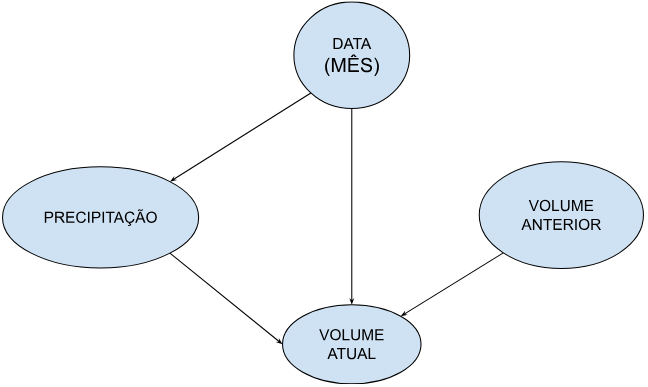

# 4. Realize o ajuste da Rede Bayesiana, considerando o Estimador Bayesiano. Interprete a distribuição de verossimilhança/condicional da variável dependente;

5. Realize a predição da variável dependente de acordo com o modelo para ao menos as últimas 5 linhas do seu conjunto de dados. Analise a qualidade das predições.

6. Em cada seção, interprete seus resultados.